# AP 155 Lab Exercise
---
## Exercise 11: Montecarlo Methods

_Instructions_:
- **Report Figures**: 
 1. initial spin configuration, you choose  $T$
 2. spin configuration after 10,000 sweeps, for $T$ above and below $T_C$
 3. magnetization and energy, for $T$ above and below $T_C$
 4. magnetization and energy with external field, for $T$ above and below $T_C$
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Pasion, Kyla Zarina
- _Student No._: 2024-09224
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# Exercise: The Two-Dimensional Ising Model

## Introduction

The Ising model describes the magnetic behavior of a material using interacting spins arranged on a lattice. Each spin can take one of two values, $S_{i,j}=\pm1$, representing spin-up and spin-down orientations.

In this exercise, you will simulate a two-dimensional Ising model using the **Metropolis Monte Carlo algorithm**. You will investigate how spin interactions, temperature, and external magnetic fields affect the system's energy and magnetization.

## 1. Setting Up the Ising Model

Consider a square lattice of size $N\times N$. Each spin interacts with its four nearest neighbors.

The energy of the system is given by the Ising Hamiltonian:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j
$$

where $J$ is the interaction strength and the summation includes each unique neighboring pair exactly once.

Use **periodic boundary conditions**, where the lattice wraps around itself so that every spin has four neighbors.

**Tasks:**

1. Create a $20\times20$ lattice with randomly initialized spins of $+1$ or $-1$.
2. Plot the initial spin configuration.
3. Write a function to calculate the total energy using:

$$
H=-J\sum_{i,j}S_{i,j}(S_{i+1,j}+S_{i,j+1})
$$

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J>0$?

## 2. Implementing the Metropolis Algorithm

The probability of a spin configuration is proportional to its Boltzmann factor:

$$
w(\mathbf S)\propto e^{-H(\mathbf S)/(k_BT)}
$$

To simulate the system, randomly select and attempt to flip one spin at a time.

For each attempted flip:

1. Randomly select a spin $S_{i,j}$.
2. Flip its orientation: $S_{i,j}'=-S_{i,j}$.
3. Calculate the energy change:

$$
\Delta H=H_{\text{new}}-H_{\text{old}}
$$

4. Accept the flip with probability:

$$
P_{\text{accept}}=\min\left(1,e^{-\Delta H/(k_BT)}\right)
$$

Let $J = T = k_B = 1$. Test your simulation for 10,000 Monte Carlo sweeps. Note that one sweep will cover $N^2$ lattice sites.

## 3. Investigating Spontaneous Magnetization

The total magnetization measures the overall alignment of spins:

$$
M=\sum_{i,j}S_{i,j}
$$

Define the (average) magnetization per spin as:

$$
m=\frac{M}{N^2}
$$

Its value ranges from $-1$ to $+1$, with values near zero indicating an approximately balanced spin distribution.

**Tasks:**

1. Run the simulation for $10^4 - 10^6$ attempted spin flips, you decide what's appropriate.
2. Record the magnetization per spin and total energy throughout the simulation.
3. Plot magnetization per spin and total energy against Monte Carlo sweeps.
4. Repeat the simulation using different random initial configurations.

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an External Magnetic Field

Modify the Hamiltonian to include a uniform external magnetic field:

$$
H(\mathbf S)=-J\sum_{\langle ij\rangle}S_iS_j-B\sum_{i,j}S_{i,j}
$$

For a single spin flip, the energy change becomes:

$$
\boxed{
\Delta H=2S_{i,j}
\left[
J(S_{i+1,j}+S_{i-1,j}+S_{i,j+1}+S_{i,j-1})+B
\right]
}
$$

**Tasks:**

Modify your simulation using $B=0.5$

1. Update the energy calculation and Metropolis algorithm.
2. Run the simulation and record energy and magnetization per spin.
3. Plot magnetization per spin against Monte Carlo sweeps.

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature

The critical temperature of the 2D Ising model is 

$$T_C \approx 2.269 \frac{J}{k_B}$$

**Task:**

Previously you let $T=1$, which is below this critical temperature  for $J=1=k_B$. Redo Sections 2, 3, and 4 by selecting a temperature **above** $T_C$.

In [2]:
# Parameters
N = 20
J = 1.0
T = 1.0
kB = 1.0
Tc = 2.269 * J / kB
sweeps_mE = 5000
seeds = [42, 15, 99, 123]
seed = 42
sweeps = 10000 
flips = N**2
steps = sweeps * flips

## 1. Setting up the Ising Model

In [3]:
def create_lattice(N, rng):
    return rng.choice([-1,1], size=(N,N))

def calculate_ham(grid, J, B=0.0):
    # Updated to include external magnetic field B
    right = np.roll(grid, shift=-1, axis=1) # S_{i,j+1}
    bottom = np.roll(grid, shift=-1, axis=0) # S_{i+1,j}
    total_interaction = np.sum(grid * (right + bottom))
    
    # H = -J * sum(S_i S_j) - B * sum(S_i)
    return -J * total_interaction - B * np.sum(grid)

**Guide questions:**
- What is the expected initial magnetization?
- What is the energy of a completely aligned lattice when $J > 0$?


## Implementating the Metropolis Algorithm

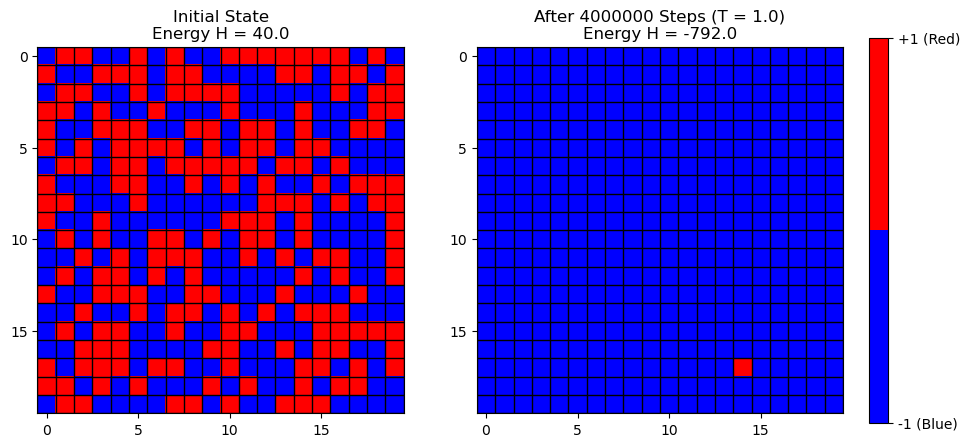

In [4]:
def metropolis_alg(grid, J, T, kB, B, rng):
    size = grid.shape[0]
    
    i = rng.integers(0, size)
    j = rng.integers(0, size)
    spin = grid[i, j]

    neighbors = (
        grid[(i-1) % size, j] + 
        grid[(i+1) % size, j] + 
        grid[i, (j-1) % size] + 
        grid[i, (j+1) % size]   
    )

    dH = 2.0 * spin * (J * neighbors + B)

    if dH <= 0 or rng.random() < np.exp(-dH / (kB * T)):
        grid[i, j] = -spin

def plot_grid(ax, grid, title):
    cmap = ListedColormap(['blue', 'red'])
    im = ax.imshow(grid, cmap=cmap, vmin=-1, vmax=1)

    ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
    ax.tick_params(which='minor', bottom=False, left=False)

    ax.set_xticks(np.arange(0, N, 5))
    ax.set_yticks(np.arange(0, N, 5))
    ax.set_title(title)
    return im

rng = np.random.default_rng(seed)
spins = create_lattice(N, rng)

initial_spins = spins.copy()
initial_energy = calculate_ham(initial_spins, J)

for _ in range(steps):
    metropolis_alg(spins, J, T, kB, 0.0, rng)

final_energy = calculate_ham(spins, J)

fig, axes = plt.subplots(1, 2, figsize=(11,5))

plot_grid(axes[0], initial_spins, f'Initial State\nEnergy H = {initial_energy}')
im = plot_grid(axes[1], spins, f'After {steps} Steps (T = {T})\nEnergy H = {final_energy}')

cbar = fig.colorbar(
    im, ax=axes.ravel().tolist(), ticks=[-1, 1], fraction=0.025, pad=0.03)

cbar.ax.set_yticklabels(['-1 (Blue)', '+1 (Red)'])
plt.show()

## 3. Investigating spontaneous magnetization

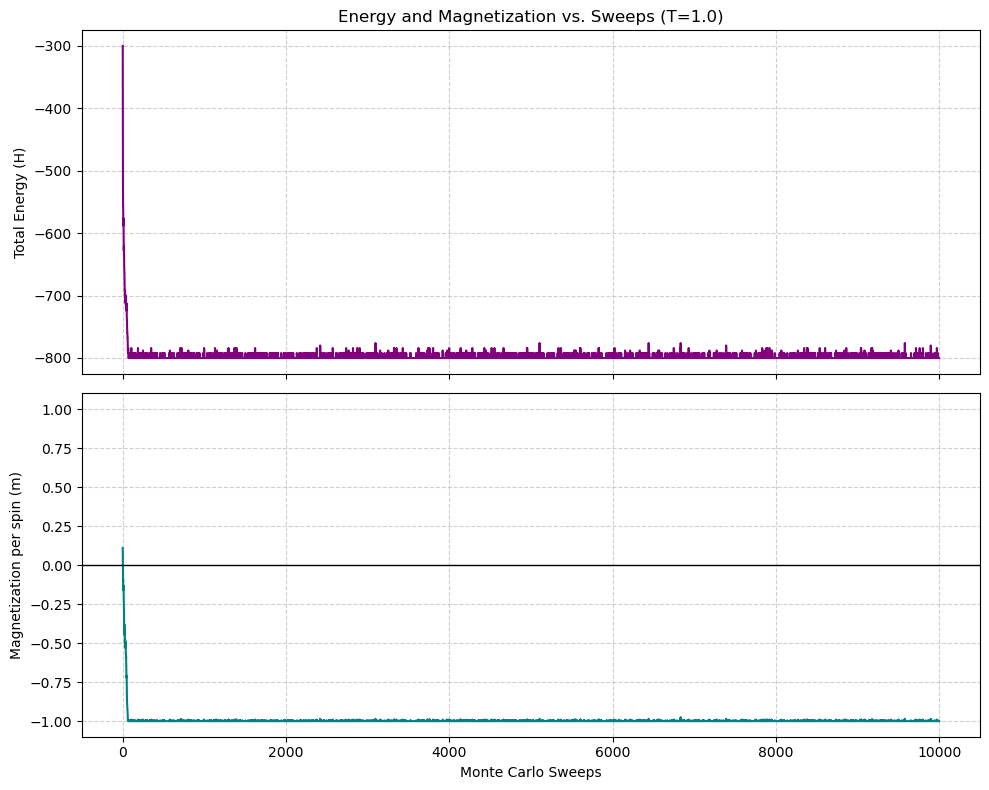

In [5]:
def run_seeds(T, B):
    runs = []
    print(f"\n--- Running for T={T}, B={B} ---")
    for s in seeds:
        rng_lattice = np.random.default_rng(s)
        rng_flip = np.random.default_rng(s + 100)
        
        S_init = create_lattice(N, rng_lattice)
        
        ms = []
        Es = []
        
        for sweep in range(sweeps_mE):
            for _ in range(N**2):
                metropolis_alg(S_init, J, T, kB, B, rng_flip)
            
            ms.append(magnetization(S_init))
            Es.append(calculate_ham(S_init, J, B))
            
        ms = np.array(ms)
        Es = np.array(Es)
        runs.append((ms, Es))
        
        print(f"Seed {s:3d}: start m = {ms[0]:+.3f}, "
              f"final <m> = {ms[-500:].mean():+.3f}, final <H> = {Es[-500:].mean():.1f}")
        
    return runs

def plot_mE(runs, T, B):
    side = "below" if T < Tc else "above"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    
    for s, (ms, Es) in zip(seeds, runs):
        ax1.plot(ms, lw=0.8, label=f"Seed {s}")
        ax2.plot(Es, lw=0.8, label=f"Seed {s}")
        
    ax1.set_ylim(-1.05, 1.05)
    ax1.set_ylabel("Magnetization per spin $m$")
    ax2.set_ylabel("Total energy $H$")
    
    for ax in (ax1, ax2):
        ax.set_xlabel("Monte Carlo sweeps")
        ax.set_title(f"$T = {T}$ ({side} $T_C$), $B = {B}$")
        ax.grid(True, linestyle='--', alpha=0.6)
        
    plt.tight_layout()
    plt.show() 

def magnetization(grid):
    return np.sum(grid) / (N**2) 

energies = []
magnetizations = []

rng = np.random.default_rng(seed=15)
spins = create_lattice(N, rng)

for sweep in range(sweeps):
    for _ in range(flips):
        metropolis_alg(spins, J, T, kB, 0.0, rng)

    current_energy = calculate_ham(spins, J)
    current_m = np.sum(spins) / (flips)

    energies.append(current_energy)
    magnetizations.append(current_m)

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

axes[0].plot(energies, color='purple', label="Energy")
axes[0].set_ylabel('Total Energy (H)')
axes[0].set_title(f'Energy and Magnetization vs. Sweeps (T={T})')
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(magnetizations, color='teal', label="Magnetization (m)")
axes[1].set_ylabel('Magnetization per spin (m)')
axes[1].set_xlabel('Monte Carlo Sweeps')
axes[1].set_ylim(-1.1, 1.1)
axes[1].axhline(0, color='black', linewidth=1, linestyle='-')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Guide questions:**
- Does the system develop spontaneous magnetization?
- Why can separate simulations produce positive or negative magnetization?
- What determines the preferred spin orientation?

## 4. Introducing an external magnetic field


--- Running for T=1.0, B=0.5 ---
Seed  42: start m = +0.255, final <m> = +1.000, final <H> = -999.6
Seed  15: start m = +0.175, final <m> = +1.000, final <H> = -999.6
Seed  99: start m = +0.215, final <m> = +1.000, final <H> = -999.6
Seed 123: start m = +0.160, final <m> = +1.000, final <H> = -999.6


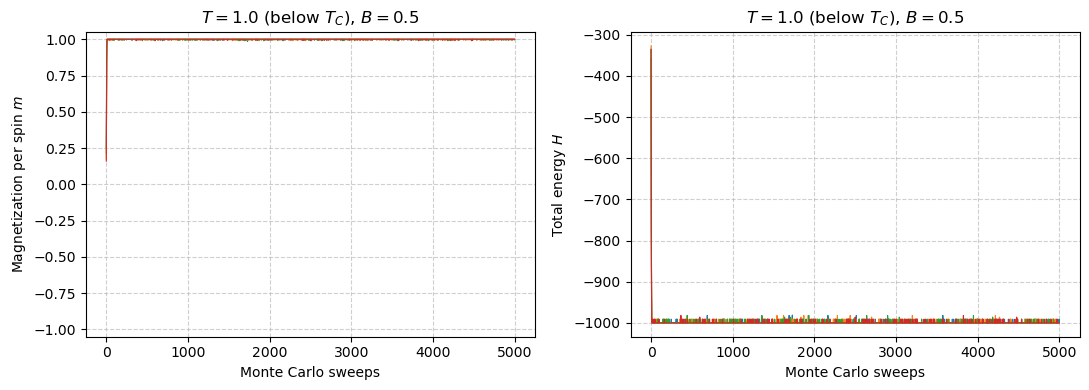

In [6]:
runs_task4 = run_seeds(T=1.0, B=0.5)
plot_mE(runs_task4, T=1.0, B=0.5) 

**Guide questions:**
- How does the external magnetic field affect spin alignment?
- Why does the system favor one magnetization direction over the other?

## 5. Critical Temperature


--- Running for T=3.0, B=0.0 ---
Seed  42: start m = -0.015, final <m> = +0.020, final <H> = -337.7
Seed  15: start m = -0.025, final <m> = +0.004, final <H> = -329.9
Seed  99: start m = -0.010, final <m> = -0.011, final <H> = -331.4
Seed 123: start m = -0.030, final <m> = +0.020, final <H> = -330.5


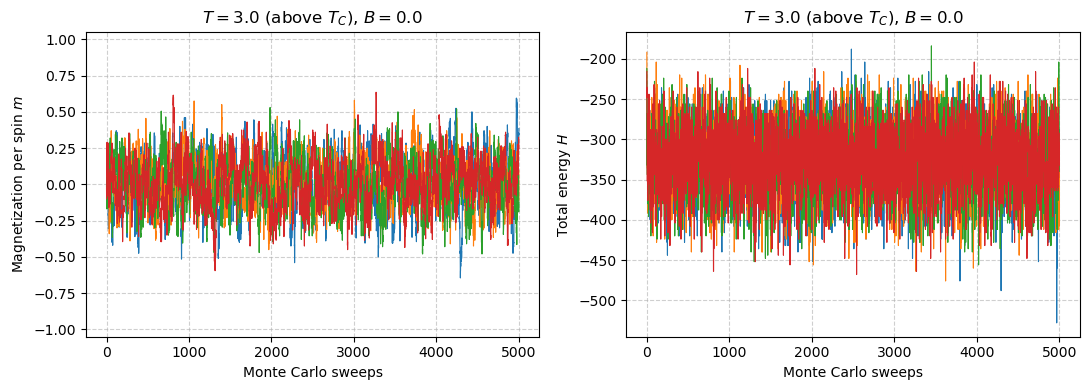


--- Running for T=3.0, B=0.5 ---
Seed  42: start m = +0.220, final <m> = +0.773, final <H> = -700.0
Seed  15: start m = +0.265, final <m> = +0.774, final <H> = -704.0


In [ ]:
# T = 3.0 (Above Tc), B = 0.0
runs_task5_B0 = run_seeds(T=3.0, B=0.0)
plot_mE(runs_task5_B0, T=3.0, B=0.0)

# T = 3.0 (Above Tc), B = 0.5
runs_task5_B05 = run_seeds(T=3.0, B=0.5)
plot_mE(runs_task5_B05, T=3.0, B=0.5)